## Library and Output Loading

In [1]:
#### Loading Libraries

from pathlib import Path
import sys

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (accuracy_score,precision_score,recall_score,
f1_score,confusion_matrix,roc_curve,roc_auc_score)

PROJECT_ROOT = Path.cwd().parents[3]

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from utils.experiment_utils.output_manager import (get_latest_output_csv)

TASK = "detection"
DATASET = "csi-imd"
MODEL = "trufor"
EXPERIMENT = "experiment1"

#### Loading Output CSV

experiment_file = (PROJECT_ROOT/ "experiments-pipeline"/ TASK/ DATASET/ MODEL/ f"{EXPERIMENT}.py")
latest_csv = get_latest_output_csv(experiment_file)
if latest_csv is None:
    raise FileNotFoundError("No output CSV found for {EXPERIMENT}.")

print(f"Using output file:\n{latest_csv}")
results_df = pd.read_csv(latest_csv)
display(results_df.head())

Using output file:
/Users/arjunmallick/1. IISc/5. M.Tech Thesis Project/2. SOTA Experiments/imdl-testbed/outputs/detection/csi-imd/trufor/experiment1_csi-imd_trufor_20260731_201345.csv


,run_timestamp,image_id,file_name,label,image_path,image_height,image_width,score,inference_time_ms,inference_status,error_type,error_message
0,2026-07-31 20:13:48,real_1,1.jpg,0,/Users/arjunmallick/1. IISc/5. M.Tech Thesis P...,531,800,0.152945,684.037292,SUCCESS,NaN,NaN
1,2026-07-31 20:13:48,real_10,10.jpg,0,/Users/arjunmallick/1. IISc/5. M.Tech Thesis P...,480,640,0.262378,406.389542,SUCCESS,NaN,NaN
2,2026-07-31 20:13:48,real_100,100.jpg,0,/Users/arjunmallick/1. IISc/5. M.Tech Thesis P...,480,640,0.291836,329.129291,SUCCESS,NaN,NaN
3,2026-07-31 20:13:48,real_101,101.jpg,0,/Users/arjunmallick/1. IISc/5. M.Tech Thesis P...,300,400,0.210913,275.662250,SUCCESS,NaN,NaN
4,2026-07-31 20:13:48,real_102,102.jpg,0,/Users/arjunmallick/1. IISc/5. M.Tech Thesis P...,300,400,0.148464,132.969417,SUCCESS,NaN,NaN


## File pre-processing

In [2]:
##### Separating SUCCESS and FAILED Cases

successful_df = (results_df[results_df["inference_status"] == "SUCCESS"].copy())
failed_df = (results_df[results_df["inference_status"] == "FAILED"].copy())

print("=" * 70)
print("Inference Summary")
print("=" * 70)

print(f"Latest CSV           : {latest_csv.name}")
print(f"Total Images         : {len(results_df)}")
print(f"Successful           : {len(successful_df)}")
print(f"Failed               : {len(failed_df)}")

Inference Summary
Latest CSV           : experiment1_csi-imd_trufor_20260731_201345.csv
Total Images         : 400
Successful           : 400
Failed               : 0


## Metrics

In [3]:
#### Accuracy, Precision, Recall and F1

THRESHOLD = 0.5
y_true = successful_df["label"].astype(int)
y_score = successful_df["score"].astype(float)
y_pred = (y_score >= THRESHOLD).astype(int)

accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true,y_pred,zero_division=0)
recall = recall_score(y_true,y_pred,zero_division=0)
f1 = f1_score(y_true,y_pred,zero_division=0,)

metrics_df = pd.DataFrame(
    {
        "Metric": ["Accuracy","Precision","Recall","F1 Score"],
        "Value": [accuracy,precision,recall,f1],
    }
)

display(metrics_df)

,Metric,Value
0,Accuracy,0.892500
1,Precision,0.890547
2,Recall,0.895000
3,F1 Score,0.892768


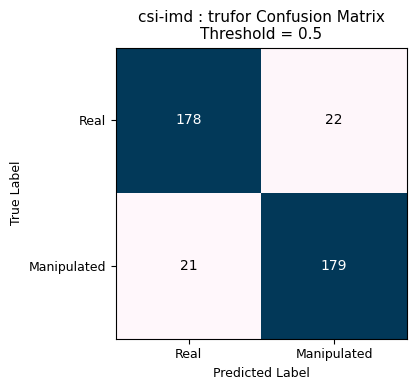

In [4]:
#### Confusion Matrix

cm = confusion_matrix(y_true,y_pred,labels=[0, 1])
plt.figure(figsize=(5, 4))
plt.imshow(cm,cmap="PuBu")

plt.title(
    f"{DATASET} : {MODEL} Confusion Matrix\n"
    f"Threshold = {THRESHOLD}", fontsize = 11)

plt.xlabel("Predicted Label", fontsize = 9)
plt.ylabel("True Label", fontsize = 9)

plt.xticks([0, 1],["Real", "Manipulated"],fontsize = 9)
plt.yticks([0, 1],["Real", "Manipulated"],fontsize = 9)

# Display Cell Values
threshold_value = cm.max() / 2
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):

        plt.text(
            j,
            i,
            f"{cm[i, j]:,}",
            ha="center",
            va="center",
            color=(
                "white"
                if cm[i, j] > threshold_value
                else "black"
            ),
        )


plt.tight_layout()
plt.show()

csi-imd ROC - AUC Analysis
AUC Score : 0.9715


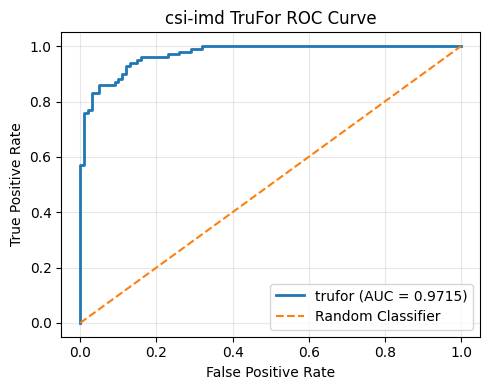

In [5]:
#### ROC - AUC Characteristics

from sklearn.metrics import (roc_curve,roc_auc_score)

 
# Compute ROC and AUC
fpr, tpr, thresholds = roc_curve(y_true,y_score)
auc_score = roc_auc_score(y_true,y_score)

 
# Display AUC
print("=" * 70)
print(f"{DATASET} ROC - AUC Analysis")
print("=" * 70)

print(f"AUC Score : {auc_score:.4f}")


 
# ROC Curve
plt.figure(figsize=(5, 4))
plt.plot(fpr,tpr,linewidth=2,label=f"{MODEL} (AUC = {auc_score:.4f})")
plt.plot([0, 1],[0, 1],linestyle="--",linewidth=1.5,label="Random Classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title( f"{DATASET} TruFor ROC Curve")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()